# 05 · Machine learning applied to the measurement: selection, stability of $A_{\rm raw}$ and Dalitz plane

**What this notebook does.** Notebook 04 builds classifiers that separate signal-like from background-like
candidates. Here the best one (gradient boosting, chosen on the cross-validated AUC) is *used*: the score cut defines
a sub-sample and we ask whether the measurement of $A_{\rm raw}$ changes. The questions, in order:

1. **Stability.** Is the counting asymmetry stable against the score threshold, within the statistical fluctuation
   expected between nested samples?
2. **Mass fit of the selected sample.** Does the double-exponential background still describe the data after the cut
   (Bayesian fit)? Same question with the frequentist fit: do the two methods and counting agree on the selected sample?
3. **Why does the mass spectrum change after the cut?** Sculpting of the mass by the classifier, or change of the
   background composition?
4. **Local asymmetry in the Dalitz plane.** Unsupervised K-means clustering (no labels) against the fixed binning
   of notebook 01 of the Bayesian analysis; null tests (phase-space simulation, charge permutation); magnet polarity.
5. **Comparison with the published analysis** (LHCb-PAPER-2013-027, same data) in the region defined by the paper.
6. **High-background sample.** Where the ML selection could really help: looser PID, much more background.

### What goes into the report (appendix *Machine-learning analysis*, *Local asymmetry in the Dalitz plane*, *Comparison*)

| Section | Report | Figure |
|---|---|---|
| 2 | Stability of $A_{\rm raw}$ under ML selection (threshold scan, magnet polarity) | `ml_nominal_threshold` |
| 3–4 | Stability: Bayesian refit; Bayesian vs frequentist vs counting | `ml_nominal_three_methods` |
| 5 | Stability: origin of the change of the mass spectrum | `ml_nominal_mass_after_cut` |
| 6 | K-means on the Dalitz plot; local asymmetries (fixed binning, K-means) | `ml_nominal_kmeans`, `ml_kmeans_selection` |
| 6 | Null tests of the local-asymmetry procedure (appendix *Dalitz*) | — (tables) |
| 7 | Region of the published analysis (*Dalitz*, *Comparison*) | `ml_nominal_dalitz_region` |
| 8 | High-background sample | `ml_nominal_high_background` |

### How to run
* Needs notebook 01 of the Bayesian analysis and notebook 04 (`results/nominal/models.json`).
* The frequentist fits use `lhcb_freq.py` of the frequentist analysis (`../Frequentist/`). If it is not in the tree,
  the blocks that need it are read from their saved results (`results/nominal/*.json`).
* From scratch about 1.5 h (Bayesian refits of 25 000 steps, 500 + 2000 phase-space and permutation tests). Each
  block saves its result and resumes from it; with the saved results the notebook takes about 5 min.

## 0 · Setup and inputs

In [1]:
import os, sys, json, time
import warnings
warnings.filterwarnings("ignore", message=".*penalty.*")
warnings.filterwarnings("ignore", message=".*l1_ratio.*")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from dataclasses import replace as _replace

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score, adjusted_rand_score, silhouette_score
from sklearn.utils.class_weight import compute_sample_weight

sys.path.insert(0, ".")        # ml_tools.py
sys.path.insert(0, "..")       # plot_style.py
import ml_tools as mn
import plot_style as ps
ps.use(); C = ps.COLORS

DATA_DIR    = "../../../opendata-project/Data"
RESULTS_DIR = os.path.join(os.getcwd(), "results", "nominal")
FIG_DIR     = os.path.join(os.getcwd(), "figures")
P = lambda name: os.path.join(RESULTS_DIR, name)
os.makedirs(FIG_DIR, exist_ok=True)
CFG = dict(bayes_nsteps=25000)          # chain length of the Bayesian refits (same as the nominal fit)

def save_json(name, obj):
    with open(P(name), "w") as f:
        json.dump(obj, f, indent=1)
    print("[saved]", os.path.relpath(P(name)))

def save_fig(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name)); plt.show(); print("[saved]", os.path.join("figures", name))

# inputs: nominal Bayesian fit (notebook 01), frequentist module (optional), classifier results (notebook 04)
bayes = mn.load_bayes_summary()
bn    = mn.import_bayes_model()
lf    = mn.import_lhcb_freq()
MU, SIGMA = bayes["nominal"]["mu"]["median"], bayes["nominal"]["sigma"]["median"]
A_BAYES, SD_BAYES = bayes["nominal"]["A"]["median"], bayes["nominal"]["A"]["sd"]
REF = json.load(open(P("models.json")))["reference_model"]
print(f"nominal Bayesian fit: mu={MU:.2f}  sigma={SIGMA:.2f} MeV  A_raw={A_BAYES:.4f} +- {SD_BAYES:.4f}")
print("reference classifier:", REF, "|  frequentist module:", "available" if lf else "NOT available (saved results are used)")

def need_freq():
    if lf is None:
        raise RuntimeError("this block must be recomputed and needs ../Frequentist/lhcb_freq.py; "
                           "the saved result in results/nominal/ was not found or does not match")
cfg_f = lf.Config(fit_window=(mn.LO, mn.HI)) if lf else None

data    = mn.load_data(DATA_DIR)
q_all   = data.B_Charge.to_numpy()
lo2 = (np.minimum(data.m12, data.m13) / 1e3) ** 2         # GeV^2, ordered pair masses of the Dalitz plane
hi2 = (np.maximum(data.m12, data.m13) / 1e3) ** 2
print(f"candidates in [{mn.LO:.0f},{mn.HI:.0f}] MeV: {len(data)}")

nominal Bayesian fit: mu=5284.39  sigma=18.00 MeV  A_raw=-0.0443 +- 0.0085
reference classifier: Gradient Boosting |  frequentist module: NOT available (saved results are used)


candidates in [5100,5600] MeV: 19731


## 1 · The reference classifier

The reference model of notebook 04 (gradient boosting: 200 trees, depth 3, learning rate 0.05, `balanced` sample
weights) is retrained on the same split and scores **all** candidates of the nominal window. The assertion checks
that the retraining reproduces the test AUC saved by notebook 04 (same seed, same split).

In [2]:
labeled = mn.weak_labels(data, MU, SIGMA)
sp = mn.make_split(labeled)
assert REF == "Gradient Boosting", "this notebook retrains the gradient-boosting reference model"
gbm = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
gbm.fit(sp["X_train"], sp["y_train"], sample_weight=sp["sw_train"])
auc_test = float(roc_auc_score(sp["y_test"], gbm.predict_proba(sp["X_test"])[:, 1]))
auc_saved = json.load(open(P("models.json")))["test_auc"][REF]
print(f"test AUC {auc_test:.4f} (saved by notebook 04: {auc_saved:.4f})")
assert abs(auc_test - auc_saved) < 1e-9, "the classifier is not reproduced: rerun notebook 04"

s_full = gbm.predict_proba(data[mn.FEATURES].to_numpy())[:, 1]      # score of every candidate of the window
print("candidates with score > 0.5:", int((s_full > 0.5).sum()), "of", len(data))

test AUC 0.8643 (saved by notebook 04: 0.8643)
candidates with score > 0.5: 15709 of 19731


## 2 · Stability of the counting asymmetry against the score threshold

For thresholds $0.1,\dots,0.9$ the counting asymmetry $A=(N^--N^+)/N$ of the selected candidates is compared with
that of the full window. Every selected sample is contained in the full one, so the expected fluctuation of the
difference is **not** the quadrature sum of the errors but $\sqrt{\sigma^2_{\rm sub}-\sigma^2_{\rm full}}$
(`nested_shift_sigma`); a bootstrap of the selected sample is shown for comparison. The two magnet polarities at
score $>0.5$ are compared as well.

**Figure `ml_nominal_threshold`.** $A_{\rm raw}$ (counting) against the threshold; the grey band is the expected
spread of the nested subsample around the full-sample value.

threshold 0.1: n= 18443 A=-0.0454  shift -0.0022 (expected +-0.0019)
threshold 0.2: n= 17669 A=-0.0451  shift -0.0019 (expected +-0.0024)
threshold 0.3: n= 17153 A=-0.0470  shift -0.0038 (expected +-0.0028)
threshold 0.4: n= 16552 A=-0.0471  shift -0.0039 (expected +-0.0031)


threshold 0.5: n= 15709 A=-0.0446  shift -0.0014 (expected +-0.0036)
threshold 0.6: n= 14531 A=-0.0463  shift -0.0031 (expected +-0.0043)


threshold 0.7: n= 12549 A=-0.0415  shift +0.0017 (expected +-0.0054)
threshold 0.8: n=  8843 A=-0.0404  shift +0.0029 (expected +-0.0079)
threshold 0.9: n=  2621 A=-0.0469  shift -0.0037 (expected +-0.0182)
magnet down (score > 0.5): n=9160  A = -0.0596 +- 0.0104
magnet up   (score > 0.5): n=6549  A = -0.0237 +- 0.0124
difference down - up: 2.22 sigma
[saved] results/nominal/threshold_stability.json


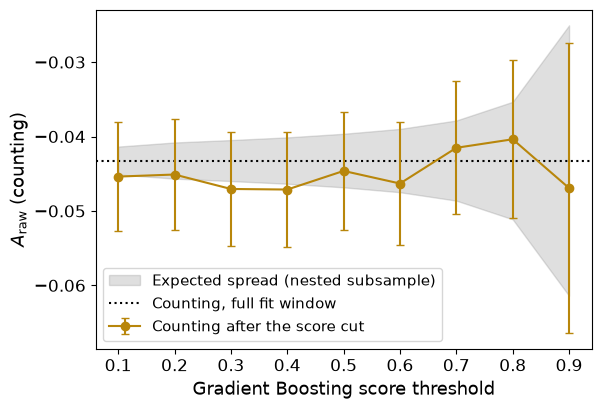

[saved] figures/ml_nominal_threshold.pdf


In [3]:
a_full, sa_full = mn.count_asym(q_all)
thr_rows = []
rng_b = np.random.default_rng(7)
for thr in np.round(np.arange(0.1, 0.91, 0.1), 2):
    sel = s_full > thr; a, sa = mn.count_asym(q_all[sel])
    boot = [mn.count_asym(q_all[sel][rng_b.integers(0, sel.sum(), sel.sum())])[0] for _ in range(200)] if sel.sum() >= 5 else []
    sn = mn.nested_shift_sigma(sa, sa_full)
    thr_rows.append({"threshold": float(thr), "n": int(sel.sum()), "A": a, "sigma_binomial": sa,
                     "sigma_bootstrap": float(np.std(boot)) if boot else None, "shift": a - a_full,
                     "sigma_shift_nested": sn, "pull_nested": (a - a_full) / sn if sn > 0 else None})
    print(f"threshold {thr:.1f}: n={sel.sum():6d} A={a:+.4f}  shift {a-a_full:+.4f} (expected +-{sn:.4f})")
mag = {}
for pol in ("down", "up"):
    sel = (s_full > 0.5) & (data.magnet.to_numpy() == pol)
    mag[pol] = dict(zip(("A", "sigma"), mn.count_asym(q_all[sel])), n=int(sel.sum()))
mag["difference_sigma"] = float(abs(mag["down"]["A"] - mag["up"]["A"]) / np.hypot(mag["down"]["sigma"], mag["up"]["sigma"]))
for pol in ("down", "up"):
    print(f"magnet {pol:4s} (score > 0.5): n={mag[pol]['n']}  A = {mag[pol]['A']:+.4f} +- {mag[pol]['sigma']:.4f}")
print(f"difference down - up: {mag['difference_sigma']:.2f} sigma")
thr = {"A_count_full": a_full, "sigma_full": sa_full, "rows": thr_rows, "magnet_threshold_0p5": mag}
save_json("threshold_stability.json", thr)

t_ = np.array([r["threshold"] for r in thr_rows]); a_ = np.array([r["A"] for r in thr_rows])
sb = np.array([r["sigma_shift_nested"] for r in thr_rows]); sbin = np.array([r["sigma_binomial"] for r in thr_rows])
fig, ax = plt.subplots(figsize=(ps.SINGLE, 4.4))
ax.fill_between(t_, a_full - sb, a_full + sb, color="gray", alpha=0.25, label="Expected spread (nested subsample)")
ax.axhline(a_full, color="k", ls=":", label="Counting, full fit window")
ax.errorbar(t_, a_, yerr=sbin, fmt="o-", capsize=3, color=C["ml"], label="Counting after the score cut")
ax.set_xlabel(f"{REF} score threshold"); ax.set_ylabel(r"$A_{\mathrm{raw}}$ (counting)")
ax.legend(loc="lower left")
save_fig(fig, "ml_nominal_threshold.pdf")

## 3 · Mass fit of the selected sample (Bayesian)

The nominal Bayesian model (same likelihood, priors and chain length as in notebook 01) is fitted to the
candidates with score $>0.5$. If the selection deformed the background, the double exponential would no longer
describe it: $A_{\rm raw}$, the background parameters and the goodness of fit are compared with the nominal fit
of the full sample. The expected shift of $A$ is again the nested-subsample fluctuation.

In [4]:
def _refit():
    sel = s_full > 0.5
    r = bn.fit(data.B_M.to_numpy()[sel], q_all[sel], bn.NOMINAL, nsteps=CFG["bayes_nsteps"])
    r.pop("_thinned", None)
    return r
refit = mn.json_cached(P("refit_selected.json"), _refit, key={"nsteps": CFG["bayes_nsteps"], "ref": REF, "threshold": 0.5})
nom = bayes["nominal"]
print(f"selected sample: n={refit['n']}  A_raw={refit['A']['median']:.4f} [{refit['A']['ci68'][0]:.4f},{refit['A']['ci68'][1]:.4f}]"
      f"  (full: {A_BAYES:.4f})  expected shift +-{mn.nested_shift_sigma(refit['A']['sd'], SD_BAYES):.4f}")
print(f"chi2/ndof selected {refit['gof']['chi2']:.1f}/{refit['gof']['ndof']}  vs full {nom['gof']['chi2']:.1f}/{nom['gof']['ndof']}")
for k in [n for n in refit["names"] if n.startswith(("lam", "f_"))]:
    print(f"  {k:9s} selected {refit[k]['median']:.4f} +- {refit[k]['sd']:.4f}   full {nom[k]['median']:.4f} +- {nom[k]['sd']:.4f}")

[resume] results/nominal/refit_selected.json
selected sample: n=15709  A_raw=-0.0451 [-0.0537,-0.0364]  (full: -0.0443)  expected shift +-0.0018
chi2/ndof selected 253.4/88  vs full 164.1/88
  lam1_pos  selected 0.0359 +- 0.0076   full 0.0351 +- 0.0078
  lam2_pos  selected 0.0071 +- 0.0007   full 0.0028 +- 0.0003
  f_pos     selected 0.2805 +- 0.0796   full 0.1137 +- 0.0300
  lam1_neg  selected 0.0305 +- 0.0042   full 0.0277 +- 0.0047
  lam2_neg  selected 0.0057 +- 0.0010   full 0.0016 +- 0.0004
  f_neg     selected 0.5041 +- 0.0837   full 0.2093 +- 0.0379


## 4 · The same question with the frequentist method; three approaches

Joint maximum-likelihood fit of the common nominal model (`lhcb_freq.fit_joint`) of the full and of the selected
sample, with the Wilks test of $A=0$ and the binned $\chi^2$ (200 bins). With the Bayesian fit of section 3 and the
counting asymmetry it gives three estimates of the shift of $A_{\rm raw}$ caused by the selection.

**Figure `ml_nominal_three_methods`.** $A_{\rm raw}$ with its uncertainty for the full sample (black) and for the
selected sample (score $>0.5$, colour) by the three methods; band: Bayesian nominal result.

[resume] results/nominal/three_methods_selected.json
                               full       selected (score>0.5)    shift expected
Bayes        -0.0443 +- 0.0085        -0.0451 +- 0.0087        -0.0008  +-0.0018
freq.        -0.0441 +- 0.0085        -0.0447 +- 0.0086        -0.0006  +-0.0012
counting     -0.0432 +- 0.0071        -0.0446 +- 0.0080        -0.0014  +-0.0036
chi2: Bayes 164/88 -> 253/88 (10 MeV bins);  freq. 442/388 -> 557/388 (200 bins)
Wilks A=0: full 5.2 sigma, selected 5.2 sigma


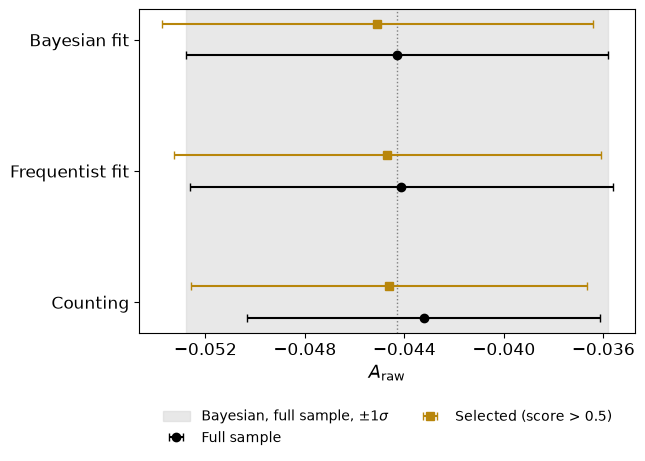

[saved] figures/ml_nominal_three_methods.pdf


In [5]:
def _freq_fit(sel):
    need_freq()
    d = pd.DataFrame({"B_Mass": data.B_M.to_numpy()[sel], "B_Charge": q_all[sel]})
    samples = lf.split_by_charge(d, col="B_Mass")
    m = lf.fit_joint(samples, cfg_f)
    t, p, _ = lf.wilks_test(m, {"A_CP": 0.0})
    g = lf.gof_joint(m, samples, cfg_f)
    return {"n": int(sel.sum()), "A": float(m.values["A_CP"]), "A_err": float(m.errors["A_CP"]), "valid": bool(m.valid),
            "accurate": bool(m.accurate), "chi2": float(g.chi2), "ndof": int(g.ndof), "wilks_t": float(t), "wilks_p": float(p)}

sel_ml = s_full > 0.5
def _three():
    freq_full, freq_sel = _freq_fit(np.ones(len(data), bool)), _freq_fit(sel_ml)
    a_cnt_sel, sa_cnt_sel = mn.count_asym(q_all[sel_ml])
    return {
        "bayes": {"full": {"A": A_BAYES, "sd": SD_BAYES, "chi2": nom["gof"]["chi2"], "ndof": nom["gof"]["ndof"]},
                  "selected": {"A": refit["A"]["median"], "sd": refit["A"]["sd"], "chi2": refit["gof"]["chi2"], "ndof": refit["gof"]["ndof"]},
                  "expected_shift_sd": mn.nested_shift_sigma(refit["A"]["sd"], SD_BAYES)},
        "frequentist": {"full": freq_full, "selected": freq_sel,
                        "expected_shift_sd": mn.nested_shift_sigma(freq_sel["A_err"], freq_full["A_err"])},
        "counting": {"full": {"A": a_full, "sd": sa_full}, "selected": {"A": a_cnt_sel, "sd": sa_cnt_sel},
                     "expected_shift_sd": mn.nested_shift_sigma(sa_cnt_sel, sa_full)},
        "threshold": 0.5, "n_full": int(len(data)), "n_selected": int(sel_ml.sum())}
three = mn.json_cached(P("three_methods_selected.json"), _three)      # saved result is used when lhcb_freq is not available
freq_full, freq_sel = three["frequentist"]["full"], three["frequentist"]["selected"]

print(f"{'':12s} {'full':>22s} {'selected (score>0.5)':>26s} {'shift':>8s} {'expected':>8s}")
for name, key in (("Bayes", "bayes"), ("freq.", "frequentist"), ("counting", "counting")):
    f, s_ = three[key]["full"], three[key]["selected"]
    sdf, sds = f.get("sd", f.get("A_err")), s_.get("sd", s_.get("A_err"))
    print(f"{name:12s} {f['A']:+.4f} +- {sdf:.4f} {'':6s} {s_['A']:+.4f} +- {sds:.4f} {'':6s} {s_['A']-f['A']:+.4f}  +-{three[key]['expected_shift_sd']:.4f}")
print(f"chi2: Bayes {three['bayes']['full']['chi2']:.0f}/{three['bayes']['full']['ndof']} -> {three['bayes']['selected']['chi2']:.0f}/"
      f"{three['bayes']['selected']['ndof']} (10 MeV bins);  freq. {freq_full['chi2']:.0f}/{freq_full['ndof']} -> "
      f"{freq_sel['chi2']:.0f}/{freq_sel['ndof']} (200 bins)")
print(f"Wilks A=0: full {np.sqrt(freq_full['wilks_t']):.1f} sigma, selected {np.sqrt(freq_sel['wilks_t']):.1f} sigma")

fig, ax = plt.subplots(figsize=(ps.SINGLE, 4.2))
_ab, _sb = three["bayes"]["full"]["A"], three["bayes"]["full"]["sd"]
ax.axvspan(_ab - _sb, _ab + _sb, color=C["shade"], alpha=0.6, zorder=0, label=r"Bayesian, full sample, $\pm1\sigma$")
ax.axvline(_ab, color=C["background"], ls=":", lw=1, zorder=0)
lab = [("bayes", "Bayesian fit", "sd"), ("frequentist", "Frequentist fit", "A_err"), ("counting", "Counting", "sd")]
for i, (k, name, e) in enumerate(lab):
    f, s_ = three[k]["full"], three[k]["selected"]
    ax.errorbar([f["A"]], [i + 0.12], xerr=[f[e]], fmt="o", color="k", capsize=3, label="Full sample" if i == 0 else None)
    ax.errorbar([s_["A"]], [i - 0.12], xerr=[s_[e]], fmt="s", color=C["ml"], capsize=3,
                label=f"Selected (score > {three['threshold']})" if i == 0 else None)
ax.set_yticks(range(len(lab))); ax.set_yticklabels([n for _, n, _ in lab])
ax.set_xlabel(r"$A_{\mathrm{raw}}$"); ax.invert_yaxis()
ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(6))
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False, fontsize=10)
save_fig(fig, "ml_nominal_three_methods.pdf")

## 5 · Why does the mass spectrum change after the cut?

The fit of the selected sample is worse ($\chi^2$ rises). Two hypotheses: (a) the classifier reconstructs the mass
from the kaon momenta (*sculpting*: the cut removes events preferentially in the sidebands in a mass-dependent way);
(b) the selection changes the composition of the background, removing the combinatorial part and keeping genuine
$B$ decays that the model does not describe. Tests:

1. the reference GBM retrained **without** the 9 momentum components (no information on the mass left);
2. the efficiency of the cut as a function of the mass (25 MeV bins);
3. the $\chi^2$ by mass region (10 MeV bins), with a Gaussian and with a Crystal Ball signal.

**Figure `ml_nominal_mass_after_cut`.** (a) mass spectrum before and after the cut, with and without momentum
features; (b) cut efficiency against mass. Hatched: region excluded from the background-like labels; grey: signal-like
window.

[resume] results/nominal/selection_mass_origin.json
full        gauss        n= 19731 A=-0.0441+-0.0085 chi2=441.7/388  by region (10 MeV): {'5100-5150': 13.7, '5150-mu-4s': 25.5, 'peak': 74.8, 'mu+4s-5600': 45.3}
full        crystal_ball n= 19731 A=-0.0447+-0.0085 chi2=406.8/386  by region (10 MeV): {'5100-5150': 15.4, '5150-mu-4s': 19.8, 'peak': 48.4, 'mu+4s-5600': 42.3}
all_20      gauss        n= 15709 A=-0.0447+-0.0086 chi2=556.7/388  by region (10 MeV): {'5100-5150': 28.1, '5150-mu-4s': 37.4, 'peak': 134.1, 'mu+4s-5600': 45.7}
all_20      crystal_ball n= 15709 A=-0.0458+-0.0086 chi2=522.3/386  by region (10 MeV): {'5100-5150': 33.3, '5150-mu-4s': 27.3, 'peak': 110.3, 'mu+4s-5600': 42.3}
no_momenta  gauss        n= 15613 A=-0.0449+-0.0087 chi2=533.1/388  by region (10 MeV): {'5100-5150': 25.5, '5150-mu-4s': 28.6, 'peak': 124.0, 'mu+4s-5600': 42.6}
no_momenta  crystal_ball n= 15613 A=-0.0459+-0.0086 chi2=501.8/386  by region (10 MeV): {'5100-5150': 30.0, '5150-mu-4s': 20.1, 'peak':

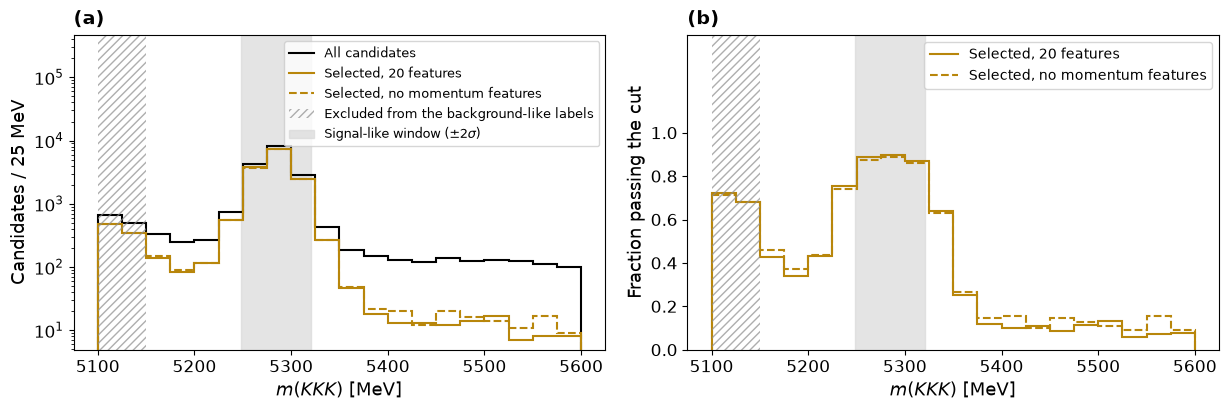

[saved] figures/ml_nominal_mass_after_cut.pdf


In [6]:
NOMOM = [f for f in mn.FEATURES if not f.endswith(("_PX", "_PY", "_PZ"))]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def _gbm_sel(feats):
    Xa, y_all = labeled[feats].to_numpy(), labeled.y.to_numpy()
    Xtr_, Xtmp_, ytr_, ytmp_ = train_test_split(Xa, y_all, test_size=0.4, stratify=y_all, random_state=42)
    Xva_, Xte_, yva_, yte_ = train_test_split(Xtmp_, ytmp_, test_size=0.5, stratify=ytmp_, random_state=42)
    sw_ = compute_sample_weight("balanced", ytr_)
    g = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
    cvs = cross_val_score(g, Xtr_, ytr_, cv=cv, scoring="roc_auc", params={"sample_weight": sw_})
    g.fit(Xtr_, ytr_, sample_weight=sw_)
    return g.predict_proba(data[feats].to_numpy())[:, 1] > 0.5, float(cvs.mean()), float(roc_auc_score(yte_, g.predict_proba(Xte_)[:, 1]))

def _chi2_regions(sel, cfg_):
    need_freq()
    smp = lf.split_by_charge(pd.DataFrame({"B_Mass": data.B_M.to_numpy()[sel], "B_Charge": q_all[sel]}), col="B_Mass")
    f = lf.fit_joint(smp, cfg_); g = lf.gof_joint(f, smp, cfg_)
    edges = np.arange(mn.LO, mn.HI + 0.1, 10.0); cen = 0.5 * (edges[1:] + edges[:-1]); tot = np.zeros(len(cen))
    for side in smp:
        curve = lf.fitted_curve(f, cfg_, side=side)
        obs, _ = np.histogram(smp[side], edges)
        exp = np.array([curve(np.linspace(a, b, 21)).mean() * (b - a) for a, b in zip(edges[:-1], edges[1:])])
        tot += (obs - exp) ** 2 / exp
    reg = {"5100-5150": cen < 5150, "5150-mu-4s": (cen > 5150) & (cen < MU - 4 * SIGMA),
           "peak": np.abs(cen - MU) < 4 * SIGMA, "mu+4s-5600": cen > MU + 4 * SIGMA}
    return {"n": int(sel.sum()), "A": float(f.values["A_CP"]), "A_err": float(f.errors["A_CP"]), "chi2": float(g.chi2), "ndof": int(g.ndof),
            "chi2_10MeV_by_region": {k: float(tot[v].sum()) for k, v in reg.items()}, "nbins_by_region": {k: int(v.sum()) for k, v in reg.items()}}

def _origin():
    out = {}
    m_all = data.B_M.to_numpy()
    e25 = np.arange(mn.LO, mn.HI + 0.1, 25.0)
    for name, feats in (("all_20", mn.FEATURES), ("no_momenta", NOMOM)):
        sel, cv_auc_, te_auc_ = _gbm_sel(feats)
        eff = [{"lo": float(a), "hi": float(b), "n": int(((m_all >= a) & (m_all < b)).sum()),
                "eff": float(sel[(m_all >= a) & (m_all < b)].mean())} for a, b in zip(e25[:-1], e25[1:])]
        out[name] = {"n_features": len(feats), "cv_auc": cv_auc_, "test_auc": te_auc_, "efficiency_vs_mass": eff,
                     "gauss": _chi2_regions(sel, cfg_f), "crystal_ball": _chi2_regions(sel, _replace(cfg_f, signal="cb"))}
    full = np.ones(len(data), bool)
    out["full"] = {"gauss": _chi2_regions(full, cfg_f), "crystal_ball": _chi2_regions(full, _replace(cfg_f, signal="cb"))}
    return out
origin = mn.json_cached(P("selection_mass_origin.json"), _origin, key={"v": 1})
for k in ("full", "all_20", "no_momenta"):
    for s in ("gauss", "crystal_ball"):
        r = origin[k][s]
        print(f"{k:11s} {s:12s} n={r['n']:6d} A={r['A']:+.4f}+-{r['A_err']:.4f} chi2={r['chi2']:.1f}/{r['ndof']}  by region (10 MeV):",
              {a: round(b, 1) for a, b in r["chi2_10MeV_by_region"].items()})
for k in ("all_20", "no_momenta"):
    print(k, f"CV AUC {origin[k]['cv_auc']:.4f}  test AUC {origin[k]['test_auc']:.4f}")
    print("  efficiency:", " ".join(f"{e['lo']:.0f}:{e['eff']:.2f}" for e in origin[k]["efficiency_vs_mass"]))

fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.3))
for key, lab_, sty in (("all_20", "Selected, 20 features", "-"), ("no_momenta", "Selected, no momentum features", "--")):
    ev = origin[key]["efficiency_vs_mass"]
    lo_ = np.array([e["lo"] for e in ev]); hi_ = np.array([e["hi"] for e in ev])
    n_ = np.array([e["n"] for e in ev]); eff = np.array([e["eff"] for e in ev])
    if key == "all_20":
        axs[0].stairs(n_, np.append(lo_, hi_[-1]), color="k", lw=1.5, label="All candidates")
    axs[0].stairs(n_ * eff, np.append(lo_, hi_[-1]), lw=1.5, ls=sty, color=C["ml"], label=lab_)
    axs[1].stairs(eff, np.append(lo_, hi_[-1]), lw=1.5, ls=sty, color=C["ml"], label=lab_)
for k_, a in enumerate(axs):
    a.axvspan(5100, 5150, facecolor="none", edgecolor="0.55", hatch="////", lw=0, alpha=0.7,
              label="Excluded from the background-like labels" if k_ == 0 else None)
    a.axvspan(MU - 2 * SIGMA, MU + 2 * SIGMA, color=C["shade"], alpha=0.7, zorder=0,
              label=r"Signal-like window ($\pm2\sigma$)" if k_ == 0 else None)
    a.set_xlabel(r"$m(KKK)$ [MeV]"); ps.letter(a, "ab"[k_])
axs[0].set_yscale("log"); axs[0].set_ylabel("Candidates / 25 MeV")
axs[0].set_ylim(axs[0].get_ylim()[0], axs[0].get_ylim()[1] * 40); axs[0].legend(loc="upper right", fontsize=9)
axs[1].set_ylabel("Fraction passing the cut"); axs[1].set_ylim(0, 1.45); axs[1].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
axs[1].legend(loc="upper right", fontsize=10)
plt.tight_layout()
save_fig(fig, "ml_nominal_mass_after_cut.pdf")

## 6 · Local asymmetry in the Dalitz plane

### 6.1 K-means (unsupervised)

Clustering on the two standardised Dalitz variables $(m^2_{\rm lo},m^2_{\rm hi})$ of all candidates of the nominal
window. The asymmetry of each cluster is compared with the global one through $S_k=(A_k-A_{\rm glob})/\sigma_k$ and
with the homogeneity statistic $\chi^2=\sum_kS_k^2$ ($K-1$ degrees of freedom). $K=8$ is fixed in advance (to be
comparable with the $8\times8$ fixed binning); $K=3$ is the silhouette optimum; the stability of the partition is
the adjusted Rand index between two seeds. The test is repeated in the signal window ($|m-\mu|<2\sigma$).

**Figure `ml_kmeans_selection`.** Inertia and silhouette against $K$. **Figure `ml_nominal_kmeans`.** The $K=8$
partition, with each candidate coloured by the significance $S_k$ of its cluster (numbers: $S_k$).

K=8: ARI=0.999  2/8 clusters beyond 3 sigma from the global asymmetry  chi2=46.4/7 p=7.3e-08;  signal window: 3 cluster, chi2=62.3/7
K=3: ARI=0.998  0/3 clusters beyond 3 sigma from the global asymmetry  chi2=15.2/2 p=4.9e-04;  signal window: 2 cluster, chi2=23.7/2


best silhouette: K = 3
[saved] results/nominal/kmeans.json


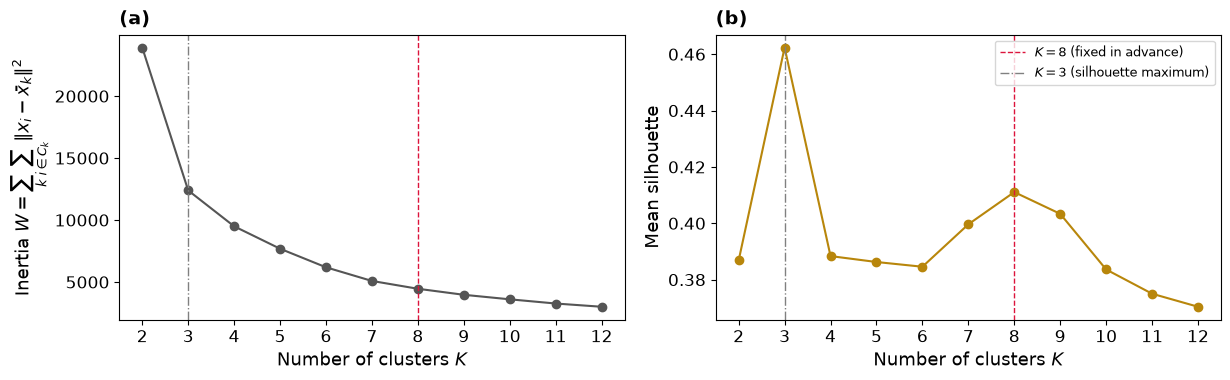

[saved] figures/ml_kmeans_selection.pdf


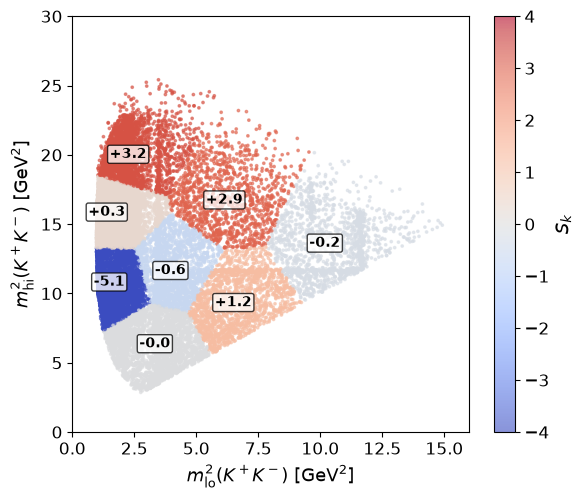

[saved] figures/ml_nominal_kmeans.pdf


In [7]:
dz = np.column_stack([lo2, hi2]); dz_s = StandardScaler().fit_transform(dz)
kmeans_res = {}
for K in (8, 3):
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(dz_s)
    km_b = KMeans(n_clusters=K, n_init=10, random_state=123).fit(dz_s)
    loc = mn.local_asym_vs_global(km.labels_, q_all)
    sigwin = np.abs(data.B_M.to_numpy() - MU) < 2 * SIGMA
    loc_sig = mn.local_asym_vs_global(km.labels_[sigwin], q_all[sigwin])
    kmeans_res[K] = {"ari_seeds": float(adjusted_rand_score(km.labels_, km_b.labels_)), "all": loc, "signal_window": loc_sig}
    print(f"K={K}: ARI={kmeans_res[K]['ari_seeds']:.3f}  {loc['n_3sigma']}/{loc['n_groups']} clusters beyond 3 sigma from the global asymmetry  "
          f"chi2={loc['chi2']:.1f}/{loc['ndof']} p={loc['p']:.1e};  signal window: {loc_sig['n_3sigma']} cluster, chi2={loc_sig['chi2']:.1f}/{loc_sig['ndof']}")
    if K == 8:
        km8 = km.labels_; np.save(P("kmeans8_labels.npy"), km8)
rng = np.random.default_rng(42); idx = rng.choice(len(dz_s), size=min(5000, len(dz_s)), replace=False)
elbow = {}
for K in range(2, 13):
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(dz_s)
    elbow[K] = {"inertia": float(km.inertia_), "silhouette": float(silhouette_score(dz_s[idx], km.labels_[idx]))}
kmeans_res["elbow_silhouette"] = elbow
kmeans_res["best_silhouette_k"] = int(max(elbow, key=lambda k: elbow[k]["silhouette"]))
print("best silhouette: K =", kmeans_res["best_silhouette_k"])
save_json("kmeans.json", kmeans_res)

Ks = sorted(elbow)
fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.0))
ps.letter(axs[0], "a"); ps.letter(axs[1], "b")
axs[0].plot(Ks, [elbow[k]["inertia"] for k in Ks], "o-", color=C["count"]); axs[0].set_ylabel(r"Inertia $W=\sum_k\sum_{i\in C_k}\|x_i-\bar x_k\|^2$")
axs[1].plot(Ks, [elbow[k]["silhouette"] for k in Ks], "o-", color=C["ml"]); axs[1].set_ylabel("Mean silhouette")
for ax in axs:
    ax.axvline(8, color=C["observed"], ls="--", lw=1, label=r"$K=8$ (fixed in advance)")
    ax.axvline(3, color=C["background"], ls="-.", lw=1, label=r"$K=3$ (silhouette maximum)")
    ax.set_xlabel("Number of clusters $K$"); ax.set_xticks(Ks)
axs[1].legend(fontsize=9, loc="upper right")
plt.tight_layout()
save_fig(fig, "ml_kmeans_selection.pdf")

fig, ax = plt.subplots(figsize=(ps.SINGLE, 5.4))
groups = {g["group"]: g for g in kmeans_res[8]["all"]["groups"]}
S_ev = np.array([groups[k]["S_vs_global"] for k in km8])
sct = ax.scatter(lo2, hi2, c=S_ev, cmap="coolwarm", vmin=-4, vmax=4, s=3, alpha=0.6, rasterized=True)
for k in range(int(km8.max()) + 1):
    sel = km8 == k
    ax.text(np.median(lo2[sel]), np.median(hi2[sel]), f"{groups[k]['S_vs_global']:+.1f}", ha="center", va="center",
            fontsize=10, weight="bold", bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.75))
ax.set_xlabel(r"$m^2_{\mathrm{lo}}(K^+K^-)$ [GeV$^2$]"); ax.set_ylabel(r"$m^2_{\mathrm{hi}}(K^+K^-)$ [GeV$^2$]")
ax.set_xlim(0, 16); ax.set_ylim(0, 30)
plt.colorbar(sct, ax=ax, label=r"$S_k$")
save_fig(fig, "ml_nominal_kmeans.pdf")

### 6.2 Fixed binning: alternative grids, null tests and magnet polarity

(a) Homogeneity test (bins with $\ge20$ candidates) with $6\times6$, $8\times8$, $10\times10$, $12\times12$ grids on
the same plane. (b) The same procedure on the **phase-space simulation** (`PhaseSpaceSimulation.root`: no
asymmetry by construction, 25 000 $B^+$ and 25 000 $B^-$): 500 sub-samples of the size of the data and the whole
simulation; the statistic must follow its $\chi^2$ distribution. (c) **Charge permutation** of the data (2000
shuffles): same occupancy and global asymmetry, no local asymmetry. (d) Nominal frequentist fit by magnet polarity,
full and selected samples.

In [8]:
import uproot
def dalitz_labels(lo2_, hi2_, nx, ny, xr=(0.0, 16.0), yr=(0.0, 30.0)):
    ix = np.floor((lo2_ - xr[0]) / (xr[1] - xr[0]) * nx).astype(int); iy = np.floor((hi2_ - yr[0]) / (yr[1] - yr[0]) * ny).astype(int)
    lab_ = ix * ny + iy
    lab_[(ix < 0) | (ix >= nx) | (iy < 0) | (iy >= ny)] = -1
    return lab_

def homogeneity(lo2_, hi2_, q, nx, ny):
    lo2_, hi2_, q = np.asarray(lo2_, float), np.asarray(hi2_, float), np.asarray(q)
    lab_ = dalitz_labels(lo2_, hi2_, nx, ny); ok = lab_ >= 0
    r = mn.local_asym_vs_global(lab_[ok], q[ok])
    return {k: r[k] for k in ("A_glob", "n_groups", "n_3sigma", "chi2", "ndof", "p", "p_at_least_nsig_if_uniform")}

def _dalitz_checks():
    out = {"binning": {}, "phase_space": {}, "magnet_fit": {}}
    sw = np.abs(data.B_M.to_numpy() - MU) < 2 * SIGMA
    for nb_ in (6, 8, 10, 12):
        out["binning"][f"{nb_}x{nb_}"] = {"all": homogeneity(lo2, hi2, q_all, nb_, nb_),
                                          "signal_window": homogeneity(lo2[sw], hi2[sw], q_all[sw], nb_, nb_)}
    # phase-space sample: kaon mass hypothesis, opposite-sign pairs (H1 opposite to the B charge)
    br = [f"H{i}_{v}" for i in (1, 2, 3) for v in ("PX", "PY", "PZ", "Charge")]
    with uproot.open(os.path.join(DATA_DIR, "PhaseSpaceSimulation.root")) as f:
        ps_ = f["PhaseSpaceTree"].arrays(br, library="pd")
    qps = (ps_.H1_Charge + ps_.H2_Charge + ps_.H3_Charge).to_numpy()
    # unlike the data, the track order is not fixed: take the two opposite-sign pairs event by event
    pp = {i: ps_[[f"H{i}_PX", f"H{i}_PY", f"H{i}_PZ"]].to_numpy() for i in (1, 2, 3)}
    cc = {i: ps_[f"H{i}_Charge"].to_numpy() for i in (1, 2, 3)}
    ee = {i: np.sqrt((pp[i] ** 2).sum(1) + mn.M_K ** 2) for i in (1, 2, 3)}
    mm = lambda a, b: np.sqrt(np.clip((ee[a] + ee[b]) ** 2 - ((pp[a] + pp[b]) ** 2).sum(1), 0, None))
    pairs = [(1, 2), (1, 3), (2, 3)]
    m_pair = np.stack([mm(a, b) for a, b in pairs], 1)
    os_mask = np.stack([cc[a] * cc[b] < 0 for a, b in pairs], 1)
    assert np.all(os_mask.sum(1) == 2) and np.all(np.abs(qps) == 1)
    m_os = m_pair[os_mask].reshape(-1, 2)
    lo2p, hi2p = (m_os.min(1) / 1e3) ** 2, (m_os.max(1) / 1e3) ** 2
    rng_ps = np.random.default_rng(11)
    for nb_ in (8, 12):
        rows = []
        for _ in range(500):
            ii = rng_ps.choice(len(qps), len(data), replace=False)
            rows.append(homogeneity(lo2p[ii], hi2p[ii], qps[ii], nb_, nb_))
        c2 = np.array([r["chi2"] for r in rows]); nd = np.array([r["ndof"] for r in rows]); pv = np.array([r["p"] for r in rows])
        n3 = np.array([r["n_3sigma"] for r in rows])
        out["phase_space"][f"{nb_}x{nb_}"] = {"n_sub": len(rows), "n_events": len(data), "mean_chi2_over_ndof": float(np.mean(c2 / nd)),
            "mean_ndof": float(nd.mean()), "frac_p_below_0.05": float(np.mean(pv < 0.05)), "frac_p_below_0.01": float(np.mean(pv < 0.01)),
            "min_p": float(pv.min()), "mean_n_3sigma": float(n3.mean()), "frac_n3sigma_ge2": float(np.mean(n3 >= 2))}
    # the 500 subsamples share the 50000 parent events, so they inherit its fluctuations: test the parent itself
    for nb_ in (8, 12):
        out["phase_space"][f"{nb_}x{nb_}"]["full_sample"] = homogeneity(lo2p, hi2p, qps, nb_, nb_)
    # permutation test on the data: charges shuffled among the candidates; p = fraction of permutations with chi2 >= observed
    rng_pm = np.random.default_rng(13)
    out["permutation"] = {}
    for nb_ in (8, 12):
        obs = out["binning"][f"{nb_}x{nb_}"]["all"]
        c2 = np.array([homogeneity(lo2, hi2, rng_pm.permutation(q_all), nb_, nb_)["chi2"] for _ in range(2000)])
        out["permutation"][f"{nb_}x{nb_}"] = {"n_perm": len(c2), "chi2_obs": obs["chi2"], "ndof": obs["ndof"],
            "mean_chi2_perm": float(c2.mean()), "sd_chi2_perm": float(c2.std()), "max_chi2_perm": float(c2.max()),
            "p_perm": float((np.sum(c2 >= obs["chi2"]) + 1) / (len(c2) + 1))}
    # magnet polarity, frequentist nominal fit, full and selected sample
    mag_all = data.magnet.to_numpy()
    for lab_, base in (("full", np.ones(len(data), bool)), ("selected", s_full > 0.5)):
        r = {pol: _freq_fit(base & (mag_all == pol)) for pol in ("down", "up")}
        r["difference_sigma"] = float(abs(r["down"]["A"] - r["up"]["A"]) / np.hypot(r["down"]["A_err"], r["up"]["A_err"]))
        out["magnet_fit"][lab_] = r
    return out
dalitz_checks = mn.json_cached(P("dalitz_checks.json"), _dalitz_checks, key={"v": 2})
for k, v in dalitz_checks["binning"].items():
    a, s_ = v["all"], v["signal_window"]
    print(f"{k:6s} all: {a['n_3sigma']}/{a['n_groups']} beyond 3 sigma, chi2={a['chi2']:.1f}/{a['ndof']} p={a['p']:.1e} | "
          f"signal window: {s_['n_3sigma']}/{s_['n_groups']}, chi2={s_['chi2']:.1f}/{s_['ndof']} p={s_['p']:.1e}")
for k, v in dalitz_checks["phase_space"].items():
    print("phase space", k, {a: round(b, 3) for a, b in v.items() if not isinstance(b, dict)})
for k, v in dalitz_checks["magnet_fit"].items():
    print(f"magnet ({k}): down {v['down']['A']:+.4f}+-{v['down']['A_err']:.4f} (n={v['down']['n']})  up {v['up']['A']:+.4f}+-{v['up']['A_err']:.4f} "
          f"(n={v['up']['n']})  diff {v['difference_sigma']:.2f} sigma")
for k, v in dalitz_checks["permutation"].items():
    print("permutation", k, {a: round(b, 4) for a, b in v.items()})
for k, v in dalitz_checks["phase_space"].items():
    print("phase space, whole sample", k, {a: (round(b, 4) if isinstance(b, float) else b) for a, b in v["full_sample"].items()})

[resume] results/nominal/dalitz_checks.json
6x6    all: 2/20 beyond 3 sigma, chi2=81.0/19 p=1.2e-09 | signal window: 2/19, chi2=90.4/18 p=1.2e-11
8x8    all: 2/32 beyond 3 sigma, chi2=80.8/31 p=2.6e-06 | signal window: 3/29, chi2=95.6/28 p=2.6e-09
10x10  all: 2/44 beyond 3 sigma, chi2=97.1/43 p=4.7e-06 | signal window: 4/40, chi2=104.4/39 p=6.9e-08
12x12  all: 1/61 beyond 3 sigma, chi2=120.0/60 p=6.8e-06 | signal window: 4/54, chi2=125.8/53 p=7.3e-08
phase space 8x8 {'n_sub': 500, 'n_events': 19731, 'mean_chi2_over_ndof': 1.162, 'mean_ndof': 29.952, 'frac_p_below_0.05': 0.128, 'frac_p_below_0.01': 0.04, 'min_p': 0.0, 'mean_n_3sigma': 0.166, 'frac_n3sigma_ge2': 0.006}
phase space 12x12 {'n_sub': 500, 'n_events': 19731, 'mean_chi2_over_ndof': 1.112, 'mean_ndof': 59.636, 'frac_p_below_0.05': 0.146, 'frac_p_below_0.01': 0.044, 'min_p': 0.0, 'mean_n_3sigma': 0.224, 'frac_n3sigma_ge2': 0.022}
magnet (full): down -0.0492+-0.0111 (n=11636)  up -0.0374+-0.0131 (n=8095)  diff 0.68 sigma
magnet (

## 7 · Comparison with LHCb-PAPER-2013-027 (same 2011 data)

The published analysis measures the local asymmetry in the region $1.2<m^2_{\rm lo}<2.0$ GeV$^2$,
$m^2_{\rm hi}<15$ GeV$^2$ (which excludes $\phi(1020)$), finding $A^{\rm reg}_{\rm raw}=-0.239\pm0.020$
($N^{\rm reg}=2581\pm55$). The region is fixed by the paper, not chosen on our data, so the comparison is *a
priori*. It is made with the three methods (frequentist fit, Bayesian fit, counting), with and without the $D^0$
veto ($\pm30$ MeV, as in the paper). The mass and charge of the candidates in the region are saved for the figure.

**Figure `ml_nominal_dalitz_region`.** (a) Dalitz plot with the resonances and the region of the published
analysis (rectangle); (b) $B^+$ and $B^-$ mass spectra in the region. *The asymmetry in (b) is the one that is
described a posteriori: the region of the paper is fixed, the plot is an illustration.*

[resume] results/nominal/paper_region.json
published: A_raw(region) = -0.239 +- 0.020;  A_raw(global) = -0.060 +- 0.007
region         n=  2146  freq -0.2367+-0.0245  bayes -0.2336+-0.0247  counting -0.1864+-0.0212
region_D0veto  n=  2146  freq -0.2367+-0.0245  bayes -0.2336+-0.0247  counting -0.1864+-0.0212
full_D0veto    n= 18744  freq -0.0493+-0.0087  bayes -0.0496+-0.0088  counting -0.0464+-0.0073


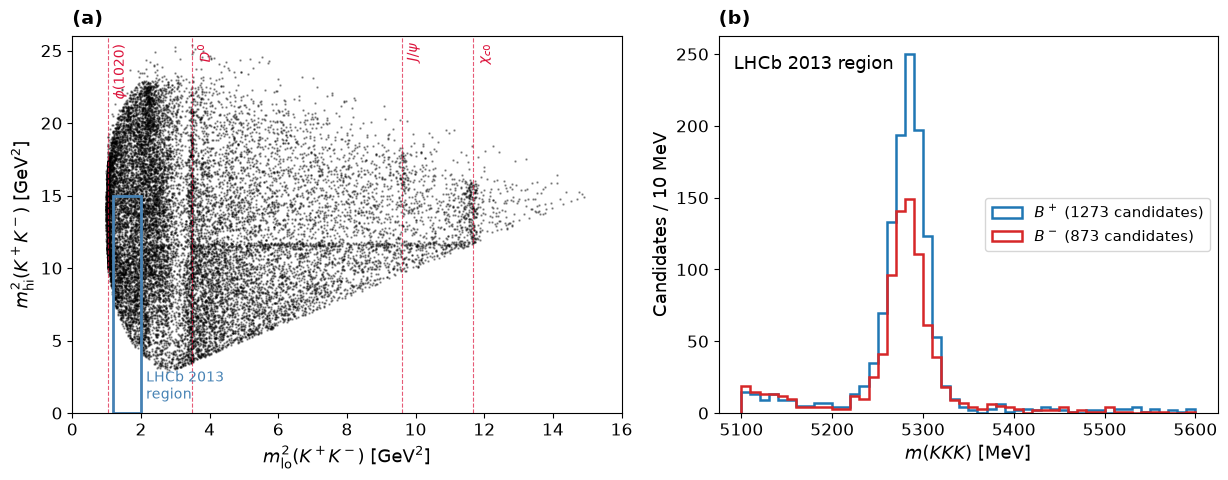

[saved] figures/ml_nominal_dalitz_region.pdf


In [9]:
def _paper_region():
    lo2_ = np.asarray(lo2, float); hi2_ = np.asarray(hi2, float)
    reg = (lo2_ > 1.2) & (lo2_ < 2.0) & (hi2_ < 15.0)
    d0 = (np.abs(data.m12.to_numpy() - bn.CHARM_STATES["D0"]) < 30) | (np.abs(data.m13.to_numpy() - bn.CHARM_STATES["D0"]) < 30)
    m_all, out = data.B_M.to_numpy(), {}
    for lab_, sel in (("region", reg), ("region_D0veto", reg & ~d0), ("full_D0veto", ~d0)):
        f = _freq_fit(sel)
        r = bn.fit(m_all[sel], q_all[sel], bn.NOMINAL, nsteps=CFG["bayes_nsteps"])
        a_c, s_c = mn.count_asym(q_all[sel])
        out[lab_] = {"n": int(sel.sum()), "freq": f, "bayes": {"A": r["A"]["median"], "sd": r["A"]["sd"], "ci68": r["A"]["ci68"],
                     "N_s": r["N_s"]["median"], "N_s_sd": r["N_s"]["sd"], "gof": r["gof"], "chain_over_tau_min": r["chain_over_tau_min"]},
                     "counting": {"A": a_c, "sd": s_c}}
        print(lab_, out[lab_]["n"], f"freq {f['A']:+.4f}+-{f['A_err']:.4f} (Z={np.sqrt(f['wilks_t']):.1f})",
              f"bayes {r['A']['median']:+.4f}+-{r['A']['sd']:.4f}  N_s={r['N_s']['median']:.0f}", f"count {a_c:+.4f}+-{s_c:.4f}")
    np.save(P("paper_region_mass_charge.npy"), np.column_stack([m_all[reg], q_all[reg]]))
    out["paper"] = {"A_raw_reg": -0.239, "A_raw_reg_err": 0.020, "N_reg": 2581, "N_reg_err": 55, "A_CP_reg": -0.226,
                    "A_raw_global": -0.060, "A_raw_global_err": 0.007, "A_CP_global": -0.043, "N_global": 22119,
                    "ref": "LHCb-PAPER-2013-027, PRL 111 (2013) 101801"}
    return out
paper_region = mn.json_cached(P("paper_region.json"), _paper_region, key={"v": 1, "nsteps": CFG["bayes_nsteps"]})
pp_ = paper_region["paper"]
print(f"published: A_raw(region) = {pp_['A_raw_reg']:+.3f} +- {pp_['A_raw_reg_err']:.3f};  A_raw(global) = {pp_['A_raw_global']:+.3f} +- {pp_['A_raw_global_err']:.3f}")
for lab_ in ("region", "region_D0veto", "full_D0veto"):
    r = paper_region[lab_]
    print(f"{lab_:14s} n={r['n']:6d}  freq {r['freq']['A']:+.4f}+-{r['freq']['A_err']:.4f}  bayes {r['bayes']['A']:+.4f}+-{r['bayes']['sd']:.4f}  "
          f"counting {r['counting']['A']:+.4f}+-{r['counting']['sd']:.4f}")

from matplotlib.patches import Rectangle
reg_mq = np.load(P("paper_region_mass_charge.npy"))
fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 5.0), gridspec_kw={"width_ratios": [1.1, 1]})
a = axs[0]
a.scatter(lo2, hi2, s=0.6, color="k", alpha=0.35, rasterized=True)
res_m = {r"$\phi(1020)$": 1.019461, r"$D^0$": 1.86484, r"$J/\psi$": 3.0969, r"$\chi_{c0}$": 3.4147}   # GeV
for lab_, mval in res_m.items():
    a.axvline(mval ** 2, color=C["model"], ls="--", lw=0.8, alpha=0.7)
    a.text(mval ** 2 + 0.15, 25.5, lab_, color=C["model"], fontsize=10, rotation=90, va="top")
a.add_patch(Rectangle((1.2, 0), 0.8, 15, fill=False, ec=C["signal"], lw=2))
a.text(2.15, 1.0, "LHCb 2013\nregion", color=C["signal"], fontsize=10)
a.set_xlim(0, 16); a.set_ylim(0, 26)
a.set_xlabel(r"$m^2_{\mathrm{lo}}(K^+K^-)$ [GeV$^2$]"); a.set_ylabel(r"$m^2_{\mathrm{hi}}(K^+K^-)$ [GeV$^2$]")
a = axs[1]
eb = np.arange(5100, 5600.1, 10)
for sgn, lab_, col in ((+1, r"$B^+$", C["pos"]), (-1, r"$B^-$", C["neg"])):
    mm_ = reg_mq[reg_mq[:, 1] == sgn, 0]
    a.hist(mm_, bins=eb, histtype="step", lw=1.8, color=col, label=f"{lab_} ({len(mm_)} candidates)")
a.set_xlabel(r"$m(KKK)$ [MeV]"); a.set_ylabel("Candidates / 10 MeV"); a.legend(loc="center right")
ps.letter(axs[0], "a"); ps.letter(axs[1], "b")
ps.panel_label(a, "LHCb 2013 region", loc="upper left")
plt.tight_layout()
save_fig(fig, "ml_nominal_dalitz_region.pdf")

## 8 · ML selection in a high-background sample

In the nominal sample the background under the peak is small and the ML selection does not improve $\sigma(A)$.
Here the starting point is a sample with a looser PID preselection ($\texttt{ProbK}>0.3$, 33 328 candidates), with
much more background, and two ways of cleaning it are compared **at equal signal efficiency**: tightening the PID
cut ($\texttt{ProbK}>0.4,\dots,0.8$) or cutting on the score of the reference GBM retrained on the weak labels of
this sample (same features, hyperparameters and weights). For each selection: nominal frequentist fit ($A$, $\sigma(A)$,
$\chi^2$, $N_s$) and the purity inside $\pm2\sigma$.

**Figure `ml_nominal_high_background`.** (a) $\sigma(A_{\rm raw})$ and (b) $A_{\rm raw}$ against the signal efficiency
for the two ways of cleaning; dotted: the nominal selection.

[resume] results/nominal/high_background.json
loose sample: 33328 {'n_signal_like': 22897, 'n_background_like': 5146, 'test_auc': 0.8952223850122022}
pid cut 0.3: n= 33328  eff_sig=1.000  purity=0.942  A=-0.0552+-0.0072  chi2=458/388
pid cut 0.4: n= 26553  eff_sig=0.859  purity=0.956  A=-0.0473+-0.0076  chi2=445/388
pid cut 0.5: n= 19731  eff_sig=0.678  purity=0.967  A=-0.0441+-0.0085  chi2=442/388
pid cut 0.6: n= 13981  eff_sig=0.498  purity=0.970  A=-0.0384+-0.0099  chi2=411/388
pid cut 0.7: n=  8649  eff_sig=0.317  purity=0.974  A=-0.0553+-0.0123  chi2=373/388
pid cut 0.8: n=  4769  eff_sig=0.178  purity=0.976  A=-0.0431+-0.0163  chi2=345/388
ml  cut 0.0: n= 33328  eff_sig=1.000  purity=0.942  A=-0.0552+-0.0072  chi2=458/388
ml  cut 0.3: n= 26744  eff_sig=0.981  purity=0.985  A=-0.0548+-0.0070  chi2=565/388
ml  cut 0.5: n= 24330  eff_sig=0.926  purity=0.993  A=-0.0560+-0.0071  chi2=603/388
ml  cut 0.7: n= 19673  eff_sig=0.777  purity=1.000  A=-0.0525+-0.0077  chi2=609/388
ml  cut 0.

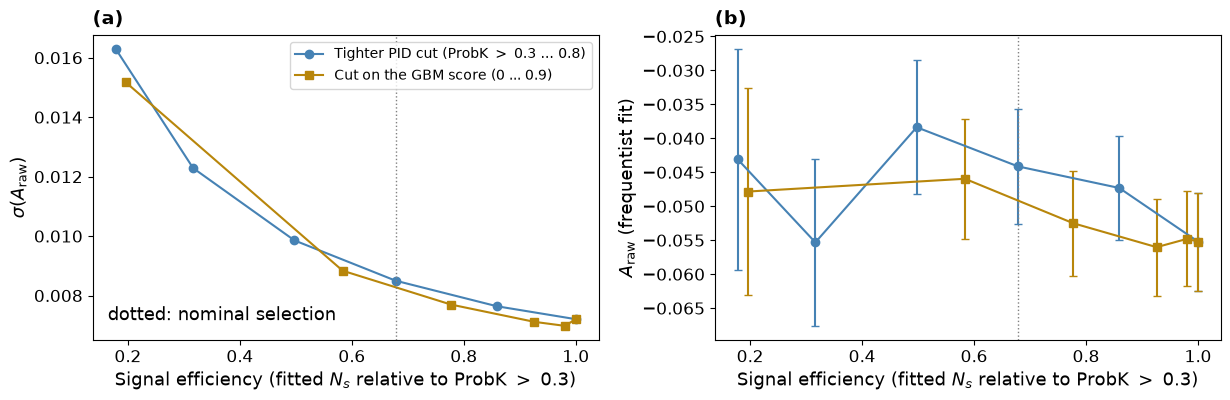

[saved] figures/ml_nominal_high_background.pdf


In [10]:
def _fit_arrays(m_, q_):
    need_freq()
    smp = lf.split_by_charge(pd.DataFrame({"B_Mass": m_, "B_Charge": q_}), col="B_Mass")
    f = lf.fit_joint(smp, cfg_f); g = lf.gof_joint(f, smp, cfg_f)
    win = np.abs(m_ - MU) < 2 * SIGMA
    return {"n": int(len(m_)), "A": float(f.values["A_CP"]), "A_err": float(f.errors["A_CP"]), "N_sig": float(f.values["N_sig"]),
            "chi2": float(g.chi2), "ndof": int(g.ndof), "valid": bool(f.valid),
            "purity_2sigma": float(0.9545 * f.values["N_sig"] / max(win.sum(), 1))}

def _high_bkg():
    loose = mn.load_data(DATA_DIR, prob_k_min=0.3)
    m_l, q_l = loose.B_M.to_numpy(), loose.B_Charge.to_numpy()
    out = {"n_loose": int(len(loose)), "pid": [], "ml": []}
    pk_min = loose[["H1_ProbK", "H2_ProbK", "H3_ProbK"]].min(axis=1).to_numpy()
    for k in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8):                     # (a) tighter PID cut on ProbK
        sel = pk_min > k
        out["pid"].append(dict(_fit_arrays(m_l[sel], q_l[sel]), cut=k))
    lab_l = mn.weak_labels(loose, MU, SIGMA)                      # (b) GBM retrained on the weak labels of the loose sample
    Xl, yl = lab_l[mn.FEATURES].to_numpy(), lab_l.y.to_numpy()
    Xtr_, Xtmp_, ytr_, ytmp_ = train_test_split(Xl, yl, test_size=0.4, stratify=yl, random_state=42)
    _, Xte_, _, yte_ = train_test_split(Xtmp_, ytmp_, test_size=0.5, stratify=ytmp_, random_state=42)
    g = GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, random_state=42)
    g.fit(Xtr_, ytr_, sample_weight=compute_sample_weight("balanced", ytr_))
    out["labels"] = {"n_signal_like": int(yl.sum()), "n_background_like": int((yl == 0).sum()),
                     "test_auc": float(roc_auc_score(yte_, g.predict_proba(Xte_)[:, 1]))}
    s_l = g.predict_proba(loose[mn.FEATURES].to_numpy())[:, 1]
    for t in (0.0, 0.3, 0.5, 0.7, 0.8, 0.9):
        sel = s_l > t
        out["ml"].append(dict(_fit_arrays(m_l[sel], q_l[sel]), cut=t))
    return out
high_bkg = mn.json_cached(P("high_background.json"), _high_bkg, key={"v": 1})
print("loose sample:", high_bkg["n_loose"], high_bkg["labels"])
ns_ref = high_bkg["pid"][0]["N_sig"]
for kind in ("pid", "ml"):
    for r in high_bkg[kind]:
        print(f"{kind:3s} cut {r['cut']:.1f}: n={r['n']:6d}  eff_sig={r['N_sig']/ns_ref:.3f}  purity={r['purity_2sigma']:.3f}  "
              f"A={r['A']:+.4f}+-{r['A_err']:.4f}  chi2={r['chi2']:.0f}/{r['ndof']}")

hb = high_bkg
fig, axs = plt.subplots(1, 2, figsize=(ps.DOUBLE, 4.2))
for kind, lab_, col, mk in (("pid", r"Tighter PID cut (ProbK $>$ 0.3 ... 0.8)", C["signal"], "o"), ("ml", "Cut on the GBM score (0 ... 0.9)", C["ml"], "s")):
    rows = [r for r in hb[kind] if r["N_sig"] / ns_ref > 0.15]
    eff = np.array([r["N_sig"] / ns_ref for r in rows])
    axs[0].plot(eff, [r["A_err"] for r in rows], mk + "-", color=col, label=lab_)
    axs[1].errorbar(eff, [r["A"] for r in rows], yerr=[r["A_err"] for r in rows], fmt=mk + "-", color=col, capsize=3, label=lab_)
nom_pid = hb["pid"][2]
for a in axs:
    a.axvline(nom_pid["N_sig"] / ns_ref, color=C["background"], ls=":", lw=1)
    a.set_xlabel("Signal efficiency (fitted $N_s$ relative to ProbK $>$ 0.3)")
axs[0].set_ylabel(r"$\sigma(A_{\mathrm{raw}})$"); axs[0].legend(loc="upper right", fontsize=10)
axs[1].set_ylabel(r"$A_{\mathrm{raw}}$ (frequentist fit)")
ps.letter(axs[0], "a"); ps.letter(axs[1], "b")
ps.panel_label(axs[0], "dotted: nominal selection", loc="lower left")
plt.tight_layout()
save_fig(fig, "ml_nominal_high_background.pdf")

## 9 · Save

In [11]:
summary = {"bayes_inputs": {"mu": MU, "sigma": SIGMA, "A_raw": A_BAYES, "sd": SD_BAYES, "reference_model": REF},
           "threshold_stability": thr, "refit_selected": refit, "three_methods_selected": three,
           "selection_mass_origin": origin, "kmeans": kmeans_res, "dalitz_checks": dalitz_checks,
           "paper_region": paper_region, "high_background": high_bkg}
assert all(v is not None for v in summary.values()), "a result is missing"
save_json("ml_selection_summary.json", summary)

[saved] results/nominal/ml_selection_summary.json
